In [1]:
# 01_hydra_baseline.ipynb
# Author: Shreed
# Official Hydra (k = 8, g = 64) on the 112 UCR datasets, default split, seed 0; comparison with the
# published results; k/g sensitivity on development datasets.

# Set up the project directories
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"        # official hydra.py
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"     # published results CSVs
DATA_DIR    = ROOT / "data" / "ucr_tsml"                  # local UCR cache (git-ignored)
RESULTS_DIR = ROOT / "01_reproduction" / "results"
FIG_DIR     = RESULTS_DIR / "figures"                     # use the figures folder that exists, or create this one
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

# Names used in the rest of this notebook
PROJECT_DIR = ROOT
REPO_DIR = ROOT / "hydra-authors-repo"

print("Project directory:", PROJECT_DIR.resolve())
print("Official repository:", REPO_DIR.resolve())
print("Dataset directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1
Official repository: /Users/shreed/PROJECTS/Hydra_1/hydra-authors-repo
Dataset directory: /Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml
Results directory: /Users/shreed/PROJECTS/Hydra_1/results/Shreed


In [2]:
PROJECT_DIR = ROOT
PROJECT_DIR

PosixPath('/Users/shreed/PROJECTS/Hydra_1/notebooks')

In [3]:
# Check the environment

import subprocess

import sys
import platform
import numpy as np
import pandas as pd
import sklearn
import torch
import aeon

environment = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "pytorch": torch.__version__,
    "aeon": aeon.__version__,
}

for key, value in environment.items():
    print(f"{key:20}: {value}")

print("\nPyTorch MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

python              : 3.12.0
platform            : macOS-15.6-arm64-arm-64bit
numpy               : 2.3.5
pandas              : 3.0.6
scikit_learn        : 1.9.1
pytorch             : 2.15.0
aeon                : 1.6.0

PyTorch MPS available: True
CUDA available: False


In [4]:
import json

with open(RESULTS_DIR / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

print("Saved environment details.")

Saved environment details.


In [5]:
# Import the authors' actual Hydra code

import importlib.util
import sys

HYDRA_SOURCE = HYDRA_CODE / "hydra.py"

assert HYDRA_SOURCE.exists(), (
    f"Could not find the official implementation: {HYDRA_SOURCE}"
)

spec = importlib.util.spec_from_file_location(
    "hydra_official_impl",
    HYDRA_SOURCE
)

hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)

Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

print("Hydra implementation:", HYDRA_SOURCE.resolve())
print("Hydra class:", Hydra)
print("SparseScaler class:", SparseScaler)

Hydra implementation: /Users/shreed/PROJECTS/Hydra_1/hydra-authors-repo/code/hydra.py
Hydra class: <class 'hydra_official_impl.Hydra'>
SparseScaler class: <class 'hydra_official_impl.SparseScaler'>


In [6]:
import inspect

print("Constructor:")
print(inspect.signature(Hydra))

print("\nForward method:")
print(inspect.getsource(Hydra.forward))

Constructor:
(input_length, k=8, g=64, seed=None)

Forward method:
    def forward(self, X):

        num_examples = X.shape[0]

        if self.divisor > 1:
            diff_X = torch.diff(X)

        Z = []

        for dilation_index in range(self.num_dilations):

            d = self.dilations[dilation_index].item()
            p = self.paddings[dilation_index].item()

            for diff_index in range(self.divisor):

                _Z = F.conv1d(X if diff_index == 0 else diff_X, self.W[dilation_index, diff_index], dilation = d, padding = p) \
                      .view(num_examples, self.h, self.k, -1)

                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)

                min_values, min_indices = _Z.min(2)
                count_min = torch.zeros(num_examples, self.h, self.k)

                count_max.scatter_add_(-1, max_indices, max_values)
                count_min.scatter_add_(-1, min_indices, torch.ones

In [7]:
# Load the authors' 112-dataset list
# (local copy in hydra-authors-repo/results/, identical to results/results_ucr112_hydra.csv in github.com/angus924/hydra)

import pandas as pd

AUTHOR_DATASET_LIST_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"

paper_results = pd.read_csv(AUTHOR_DATASET_LIST_CSV)
paper_results.columns = paper_results.columns.str.strip().str.lower()

assert "dataset" in paper_results.columns, (
    f"Expected a 'dataset' column. Found: {paper_results.columns.tolist()}"
)

PAPER_UCR112_DATASETS = (
    paper_results["dataset"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)

print("Number of unique datasets:", len(PAPER_UCR112_DATASETS))
print("First 20 dataset names:")
print(PAPER_UCR112_DATASETS[:20])

if len(PAPER_UCR112_DATASETS) != 112:
    raise RuntimeError(
        f"Expected 112 dataset names, found {len(PAPER_UCR112_DATASETS)}. "
        "Check the downloaded author results file before continuing."
    )

Number of unique datasets: 112
First 20 dataset names:
['ACSF1', 'Adiac', 'ArrowHead', 'BME', 'Beef', 'BeetleFly', 'BirdChicken', 'CBF', 'Car', 'Chinatown', 'ChlorineConcentration', 'CinCECGTorso', 'Coffee', 'Computers', 'CricketX', 'CricketY', 'CricketZ', 'Crop', 'DiatomSizeReduction', 'DistalPhalanxOutlineAgeGroup']


In [8]:
# Define the dataset loader

from aeon.datasets import load_classification
import numpy as np


def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    """
    Load the predefined train/test split for a UCR classification dataset.

    Returns
    -------
    X_train : np.ndarray
        Shape: (n_train, n_channels, n_timepoints)
    y_train : np.ndarray
        Training labels.
    X_test : np.ndarray
        Shape: (n_test, n_channels, n_timepoints)
    y_test : np.ndarray
        Test labels.
    """
    X_train, y_train = load_classification(
        name=dataset_name,
        split="train",
        extract_path=str(extract_path),
        return_metadata=False,
    )

    X_test, y_test = load_classification(
        name=dataset_name,
        split="test",
        extract_path=str(extract_path),
        return_metadata=False,
    )

    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)

    # Consistent label representation across train and test.
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(
            f"{dataset_name}: Expected 3D input arrays. "
            f"Got train={X_train.shape}, test={X_test.shape}"
        )

    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(
            f"{dataset_name}: Expected univariate data for this "
            f"baseline. Train={X_train.shape}, test={X_test.shape}"
        )

    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(
            f"{dataset_name}: Train/test series lengths differ."
        )

    if len(X_train) != len(y_train) or len(X_test) != len(y_test):
        raise ValueError(
            f"{dataset_name}: Number of samples does not match labels."
        )

    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(
            f"{dataset_name}: Test labels include classes absent from training."
        )

    return X_train, y_train, X_test, y_test

In [9]:
# Test the dataset download on one official dataset

SMOKE_TEST_DATASET = (
    "Coffee" if "Coffee" in PAPER_UCR112_DATASETS
    else PAPER_UCR112_DATASETS[0]
)

X_train, y_train, X_test, y_test = load_ucr_dataset(
    SMOKE_TEST_DATASET
)

print("Dataset:", SMOKE_TEST_DATASET)
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)

print("Number of classes:", len(np.unique(y_train)))
print("Training class counts:")
print(pd.Series(y_train).value_counts().sort_index())

Dataset: Coffee
Training features: (28, 1, 286)
Training labels: (28,)
Test features: (28, 1, 286)
Test labels: (28,)
Number of classes: 2
Training class counts:
0    14
1    14
Name: count, dtype: int64


In [10]:
for path in sorted(DATA_DIR.glob("*")):
    print(path)

/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/ACSF1
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Adiac
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/ArrowHead
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/BME
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Beef
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/BeetleFly
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/BirdChicken
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/CBF
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Car
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Chinatown
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/ChlorineConcentration
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/CinCECGTorso
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Coffee
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Computers
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/CricketX
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/CricketY
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/CricketZ
/Users/shreed/PROJECTS/Hydra_1/data/ucr_tsml/Crop
/Users/shreed/PROJECTS/Hydra_1/data

In [11]:
# Define the evaluation function

from time import perf_counter

from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

import torch


def run_hydra_baseline(
    dataset_name,
    seed=0,
    batch_size=256,
):
    """
    Run the authors' original Hydra transform + SparseScaler
    + RidgeClassifierCV pipeline on one UCR dataset.
    """

    # 1. Load the predefined train/test split.
    X_train, y_train, X_test, y_test = load_ucr_dataset(
        dataset_name
    )

    # The original Hydra implementation expects a tensor with shape
    # (n_examples, 1, series_length).
    X_train_tensor = torch.as_tensor(
        np.ascontiguousarray(X_train),
        dtype=torch.float32,
    )

    X_test_tensor = torch.as_tensor(
        np.ascontiguousarray(X_test),
        dtype=torch.float32,
    )

    # 2. Initialise the original Hydra implementation.
    # Defaults: k=8, g=64.
    transform = Hydra(
        input_length=X_train_tensor.shape[-1],
        seed=seed,
    )

    # 3. Extract features. Use CPU and disable gradient tracking.
    train_start = perf_counter()

    with torch.inference_mode():
        Z_train = transform.batch(
            X_train_tensor,
            batch_size=batch_size,
        )

    # 4. Fit the scaler on training features only.
    scaler = SparseScaler()
    Z_train = scaler.fit_transform(Z_train)

    # 5. Train the ridge classifier.
    classifier = RidgeClassifierCV(
        alphas=np.logspace(-3, 3, 10)
    )

    classifier.fit(
        Z_train.detach().cpu().numpy(),
        y_train,
    )

    train_seconds = perf_counter() - train_start

    # 6. Transform and predict on the held-out test data.
    test_start = perf_counter()

    with torch.inference_mode():
        Z_test = transform.batch(
            X_test_tensor,
            batch_size=batch_size,
        )

    Z_test = scaler.transform(Z_test)

    predictions = classifier.predict(
        Z_test.detach().cpu().numpy()
    )

    test_seconds = perf_counter() - test_start

    # 7. Evaluate predictions.
    result = {
        "dataset": dataset_name,
        "n_train": len(y_train),
        "n_test": len(y_test),
        "series_length": X_train.shape[-1],
        "n_features": Z_train.shape[1],
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "train_seconds": train_seconds,
        "test_seconds": test_seconds,
        "seed": seed,
        "k": 8,
        "g": 64,
    }

    return result, y_test, predictions

In [12]:
# Execute the baseline
baseline_result, y_true, y_pred = run_hydra_baseline(
    SMOKE_TEST_DATASET,
    seed=0,
)

display(pd.DataFrame([baseline_result]).round(4))

,dataset,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_seconds,test_seconds,seed,k,g
0,Coffee,28,28,286,6144,1.0,1.0,0.1686,0.13,0,8,64


In [13]:
baseline_result, y_true, y_pred = run_hydra_baseline(
    SMOKE_TEST_DATASET,
    seed=0,
)

display(pd.DataFrame([baseline_result]).round(4))

,dataset,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_seconds,test_seconds,seed,k,g
0,Coffee,28,28,286,6144,1.0,1.0,0.1377,0.1264,0,8,64


In [14]:
# Download and validate all 112 datasets
from tqdm.auto import tqdm

dataset_manifest = []
dataset_failures = []

for dataset_name in tqdm(
    PAPER_UCR112_DATASETS,
    desc="Checking official Hydra benchmark datasets",
):
    try:
        Xtr, ytr, Xte, yte = load_ucr_dataset(dataset_name)

        dataset_manifest.append({
            "dataset": dataset_name,
            "n_train": len(ytr),
            "n_test": len(yte),
            "n_classes": len(np.unique(ytr)),
            "series_length": Xtr.shape[-1],
            "n_channels": Xtr.shape[1],
            "train_shape": str(Xtr.shape),
            "test_shape": str(Xte.shape),
            "status": "ok",
        })

    except Exception as exc:
        dataset_failures.append({
            "dataset": dataset_name,
            "error_type": type(exc).__name__,
            "error_message": str(exc),
        })

manifest_df = pd.DataFrame(dataset_manifest)
failures_df = pd.DataFrame(dataset_failures)

manifest_df.to_csv(
    RESULTS_DIR / "ucr112_dataset_manifest.csv",
    index=False,
)

failures_df.to_csv(
    RESULTS_DIR / "ucr112_dataset_failures.csv",
    index=False,
)

print("Expected datasets:", len(PAPER_UCR112_DATASETS))
print("Successfully loaded:", len(manifest_df))
print("Failed datasets:", len(failures_df))

display(manifest_df.head(10))

if not failures_df.empty:
    display(failures_df)

/Users/shreed/PROJECTS/Hydra_1/hydra_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Checking official Hydra benchmark datasets:   0%|          | 0/112 [00:00<?, ?it/s]

Checking official Hydra benchmark datasets: 100%|██████████| 112/112 [00:12<00:00,  8.88it/s]

Expected datasets: 112
Successfully loaded: 112
Failed datasets: 0


,dataset,n_train,n_test,n_classes,series_length,n_channels,train_shape,test_shape,status
0,ACSF1,100,100,10,1460,1,"(100, 1, 1460)","(100, 1, 1460)",ok
1,Adiac,390,391,37,176,1,"(390, 1, 176)","(391, 1, 176)",ok
2,ArrowHead,36,175,3,251,1,"(36, 1, 251)","(175, 1, 251)",ok
3,BME,30,150,3,128,1,"(30, 1, 128)","(150, 1, 128)",ok
4,Beef,30,30,5,470,1,"(30, 1, 470)","(30, 1, 470)",ok
5,BeetleFly,20,20,2,512,1,"(20, 1, 512)","(20, 1, 512)",ok
6,BirdChicken,20,20,2,512,1,"(20, 1, 512)","(20, 1, 512)",ok
7,CBF,30,900,3,128,1,"(30, 1, 128)","(900, 1, 128)",ok
8,Car,60,60,4,577,1,"(60, 1, 577)","(60, 1, 577)",ok
9,Chinatown,20,343,2,24,1,"(20, 1, 24)","(343, 1, 24)",ok


In [15]:
# Check the dataset manifest

if not manifest_df.empty:
    print("Series-length distribution:")
    display(manifest_df["series_length"].describe())

    print("\nNumber of classes:")
    display(
        manifest_df["n_classes"]
        .value_counts()
        .sort_index()
        .rename_axis("n_classes")
        .to_frame("n_datasets")
    )

    print("\nLargest training sets:")
    display(
        manifest_df.sort_values(
            "n_train",
            ascending=False,
        ).head(10)
    )

    print("\nSmallest training sets:")
    display(
        manifest_df.sort_values(
            "n_train",
            ascending=True,
        ).head(10)
    )

Series-length distribution:


count     112.000000
mean      551.357143
std       591.688390
min        15.000000
25%       134.750000
50%       315.000000
75%       720.000000
max      2844.000000
Name: series_length, dtype: float64


Number of classes:


,n_datasets
n_classes,
2,40
3,17
4,9
5,7
6,7
7,5
8,5
10,2
11,1



Largest training sets:


,dataset,n_train,n_test,n_classes,series_length,n_channels,train_shape,test_shape,status
28,ElectricDevices,8926,7711,7,96,1,"(8926, 1, 96)","(7711, 1, 96)",ok
17,Crop,7200,16800,24,46,1,"(7200, 1, 46)","(16800, 1, 46)",ok
36,FordB,3636,810,2,500,1,"(3636, 1, 500)","(810, 1, 500)",ok
35,FordA,3601,1320,2,500,1,"(3601, 1, 500)","(1320, 1, 500)",ok
69,PhalangesOutlinesCorrect,1800,858,2,80,1,"(1800, 1, 80)","(858, 1, 80)",ok
66,NonInvasiveFetalECGThorax2,1800,1965,42,750,1,"(1800, 1, 750)","(1965, 1, 750)",ok
65,NonInvasiveFetalECGThorax1,1800,1965,42,750,1,"(1800, 1, 750)","(1965, 1, 750)",ok
106,Wafer,1000,6164,2,152,1,"(1000, 1, 152)","(6164, 1, 152)",ok
44,HandOutlines,1000,370,2,2709,1,"(1000, 1, 2709)","(370, 1, 2709)",ok
100,TwoPatterns,1000,4000,4,128,1,"(1000, 1, 128)","(4000, 1, 128)",ok



Smallest training sets:


,dataset,n_train,n_test,n_classes,series_length,n_channels,train_shape,test_shape,status
18,DiatomSizeReduction,16,306,4,345,1,"(16, 1, 345)","(306, 1, 345)",ok
50,InsectEPGSmallTrain,17,249,3,601,1,"(17, 1, 601)","(249, 1, 601)",ok
64,MoteStrain,20,1252,2,84,1,"(20, 1, 84)","(1252, 1, 84)",ok
5,BeetleFly,20,20,2,512,1,"(20, 1, 512)","(20, 1, 512)",ok
6,BirdChicken,20,20,2,512,1,"(20, 1, 512)","(20, 1, 512)",ok
80,Rock,20,50,4,2844,1,"(20, 1, 2844)","(50, 1, 2844)",ok
85,ShapeletSim,20,180,2,500,1,"(20, 1, 500)","(180, 1, 500)",ok
9,Chinatown,20,343,2,24,1,"(20, 1, 24)","(343, 1, 24)",ok
89,SonyAIBORobotSurface1,20,601,2,70,1,"(20, 1, 70)","(601, 1, 70)",ok
24,ECGFiveDays,23,861,2,136,1,"(23, 1, 136)","(861, 1, 136)",ok


In [16]:
# Select up to three successfully loaded datasets.
INITIAL_DATASETS = (
    manifest_df["dataset"].head(3).tolist()
    if not manifest_df.empty
    else [SMOKE_TEST_DATASET]
)

print("Initial baseline datasets:", INITIAL_DATASETS)

Initial baseline datasets: ['ACSF1', 'Adiac', 'ArrowHead']


In [17]:
# Run Hydra on the selected datasets
multi_dataset_results = []

for dataset_name in INITIAL_DATASETS:
    try:
        result, y_true, y_pred = run_hydra_baseline(
            dataset_name,
            seed=0,
        )
        multi_dataset_results.append(result)

        print(
            f"{dataset_name}: "
            f"accuracy={result['accuracy']:.4f}, "
            f"macro-F1={result['macro_f1']:.4f}, "
            f"train={result['train_seconds']:.2f}s"
        )

    except Exception as exc:
        print(f"FAILED: {dataset_name}: {exc}")

multi_dataset_df = pd.DataFrame(multi_dataset_results)

multi_dataset_df.to_csv(
    RESULTS_DIR / "hydra_baseline_initial_datasets.csv",
    index=False,
)

display(multi_dataset_df.round(4))

ACSF1: accuracy=0.8600, macro-F1=0.8603, train=1.93s
Adiac: accuracy=0.8184, macro-F1=0.8097, train=0.79s
ArrowHead: accuracy=0.8343, macro-F1=0.8343, train=0.16s


,dataset,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_seconds,test_seconds,seed,k,g
0,ACSF1,100,100,1460,8192,0.8600,0.8603,1.9283,1.9267,0,8,64
1,Adiac,390,391,176,5120,0.8184,0.8097,0.7947,0.8092,0,8,64
2,ArrowHead,36,175,251,5120,0.8343,0.8343,0.1559,0.4822,0,8,64


In [18]:
# Load the reference results (local copy of the authors' published results)
OFFICIAL_RESULTS_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"

official_hydra_results = pd.read_csv(OFFICIAL_RESULTS_CSV)
official_hydra_results.columns = (
    official_hydra_results.columns.str.strip().str.lower()
)

display(official_hydra_results.head())
print("Reference result columns:", official_hydra_results.columns.tolist())

,dataset,accuracy,time_training_seconds,time_test_seconds
0,ACSF1,0.806667,5.436658,5.202016
1,Adiac,0.815772,1.701166,1.425524
2,ArrowHead,0.869714,0.288209,1.086603
3,BME,1.000000,0.192204,0.375812
4,Beef,0.805556,0.478797,0.368553


Reference result columns: ['dataset', 'accuracy', 'time_training_seconds', 'time_test_seconds']


In [19]:
# Inspect the reference result for your smoke-test dataset
reference_match = official_hydra_results[
    official_hydra_results["dataset"].astype(str).str.lower()
    == SMOKE_TEST_DATASET.lower()
]

print("Dataset:", SMOKE_TEST_DATASET)

if reference_match.empty:
    print("No matching reference result found in the author's CSV.")
else:
    display(reference_match)
    display(pd.DataFrame([baseline_result]))

Dataset: Coffee


,dataset,accuracy,time_training_seconds,time_test_seconds
12,Coffee,0.997619,0.320494,0.219928


,dataset,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_seconds,test_seconds,seed,k,g
0,Coffee,28,28,286,6144,1.0,1.0,0.137688,0.126421,0,8,64


In [20]:
# Experimental configuration

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from time import perf_counter
from tqdm.auto import tqdm
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# Six datasets chosen for the initial group-project benchmark.
SELECTED_DATASETS = [
    "ECG200",
    "GunPoint",
    "Coffee",
    "ItalyPowerDemand",
    "TwoLeadECG",
    "Wafer",
]

# Validate against the authors' published 112-dataset list.
paper_name_lookup = {
    name.lower(): name for name in PAPER_UCR112_DATASETS
}

missing = [
    name for name in SELECTED_DATASETS
    if name.lower() not in paper_name_lookup
]

if missing:
    raise ValueError(
        f"These datasets are missing from the authors' list: {missing}"
    )

SELECTED_DATASETS = [
    paper_name_lookup[name.lower()]
    for name in SELECTED_DATASETS
]

# Set to True only when you intend to run the default baseline on
# all 112 datasets instead of the initial six.
RUN_ALL_112 = True

BASELINE_DATASETS = (
    PAPER_UCR112_DATASETS
    if RUN_ALL_112
    else SELECTED_DATASETS
)

# Hydra defaults from the paper.
DEFAULT_K = 8
DEFAULT_G = 64
BASELINE_SEED = 0
BATCH_SIZE = 256

BASELINE_RESULTS_PATH = (
    RESULTS_DIR / "hydra_default_baseline.csv"
)

HYPERPARAM_RESULTS_PATH = (
    RESULTS_DIR / "hydra_kg_sensitivity.csv"
)

print("Datasets for the baseline:", len(BASELINE_DATASETS))
print(BASELINE_DATASETS)
print("Default k:", DEFAULT_K)
print("Default g:", DEFAULT_G)
print("Kernels per dilation:", DEFAULT_K * DEFAULT_G)

Datasets for the baseline: 112
['ACSF1', 'Adiac', 'ArrowHead', 'BME', 'Beef', 'BeetleFly', 'BirdChicken', 'CBF', 'Car', 'Chinatown', 'ChlorineConcentration', 'CinCECGTorso', 'Coffee', 'Computers', 'CricketX', 'CricketY', 'CricketZ', 'Crop', 'DiatomSizeReduction', 'DistalPhalanxOutlineAgeGroup', 'DistalPhalanxOutlineCorrect', 'DistalPhalanxTW', 'ECG200', 'ECG5000', 'ECGFiveDays', 'EOGHorizontalSignal', 'EOGVerticalSignal', 'Earthquakes', 'ElectricDevices', 'EthanolLevel', 'FaceAll', 'FaceFour', 'FacesUCR', 'FiftyWords', 'Fish', 'FordA', 'FordB', 'FreezerRegularTrain', 'FreezerSmallTrain', 'GunPoint', 'GunPointAgeSpan', 'GunPointMaleVersusFemale', 'GunPointOldVersusYoung', 'Ham', 'HandOutlines', 'Haptics', 'Herring', 'HouseTwenty', 'InlineSkate', 'InsectEPGRegularTrain', 'InsectEPGSmallTrain', 'InsectWingbeatSound', 'ItalyPowerDemand', 'LargeKitchenAppliances', 'Lightning2', 'Lightning7', 'Mallat', 'Meat', 'MedicalImages', 'MiddlePhalanxOutlineAgeGroup', 'MiddlePhalanxOutlineCorrect', 'M

In [21]:
# Configurable evaluation using the authors' implementation

def evaluate_hydra(
    dataset_name,
    k=8,
    g=64,
    seed=0,
    batch_size=256,
):
    """
    Evaluate the authors' original Hydra transform with
    SparseScaler and RidgeClassifierCV on a predefined UCR split.

    Returns a dictionary of metrics.
    """

    # 1. Load the predefined UCR training and test splits.
    X_train, y_train, X_test, y_test = load_ucr_dataset(
        dataset_name
    )

    X_train_tensor = torch.as_tensor(
        np.ascontiguousarray(X_train),
        dtype=torch.float32,
    )

    X_test_tensor = torch.as_tensor(
        np.ascontiguousarray(X_test),
        dtype=torch.float32,
    )

    # 2. Initialise the original Hydra implementation.
    # The constructor creates the random kernels.
    transform = Hydra(
        input_length=X_train_tensor.shape[-1],
        k=k,
        g=g,
        seed=seed,
    )

    # 3. Extract training features.
    transform_start = perf_counter()

    with torch.inference_mode():
        Z_train = transform.batch(
            X_train_tensor,
            batch_size=batch_size,
        )

    train_transform_seconds = (
        perf_counter() - transform_start
    )

    # 4. Fit SparseScaler on training features only.
    # Then train the same type of classifier used in the
    # official repository's README.
    fit_start = perf_counter()

    scaler = SparseScaler()
    Z_train_scaled = scaler.fit_transform(Z_train)

    classifier = RidgeClassifierCV(
        alphas=np.logspace(-3, 3, 10)
    )

    classifier.fit(
        Z_train_scaled.detach().cpu().numpy(),
        y_train,
    )

    classifier_fit_seconds = perf_counter() - fit_start

    # 5. Extract test features and predict.
    test_start = perf_counter()

    with torch.inference_mode():
        Z_test = transform.batch(
            X_test_tensor,
            batch_size=batch_size,
        )

    Z_test_scaled = scaler.transform(Z_test)

    predictions = classifier.predict(
        Z_test_scaled.detach().cpu().numpy()
    )

    test_seconds = perf_counter() - test_start

    # 6. Calculate evaluation metrics.
    total_train_seconds = (
        train_transform_seconds + classifier_fit_seconds
    )

    return {
        "dataset": dataset_name,
        "seed": seed,
        "k": k,
        "g": g,
        "kernels_per_dilation": k * g,
        "n_train": len(y_train),
        "n_test": len(y_test),
        "series_length": X_train.shape[-1],
        "n_features": Z_train.shape[1],
        "accuracy": accuracy_score(y_test, predictions),
        "macro_f1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "train_transform_seconds": train_transform_seconds,
        "classifier_fit_seconds": classifier_fit_seconds,
        "train_seconds": total_train_seconds,
        "test_seconds": test_seconds,
    }

In [22]:
# Default Hydra benchmark

baseline_results = []
baseline_failures = []

for dataset_name in tqdm(
    BASELINE_DATASETS,
    desc="Running default Hydra",
):
    try:
        result = evaluate_hydra(
            dataset_name=dataset_name,
            k=DEFAULT_K,
            g=DEFAULT_G,
            seed=BASELINE_SEED,
            batch_size=BATCH_SIZE,
        )

        baseline_results.append(result)

        # Checkpoint results after every successful dataset.
        pd.DataFrame(baseline_results).to_csv(
            BASELINE_RESULTS_PATH,
            index=False,
        )

        print(
            f"{dataset_name}: "
            f"accuracy={result['accuracy']:.4f}, "
            f"macro-F1={result['macro_f1']:.4f}, "
            f"train={result['train_seconds']:.2f}s, "
            f"test={result['test_seconds']:.2f}s"
        )

    except Exception as exc:
        baseline_failures.append({
            "dataset": dataset_name,
            "error_type": type(exc).__name__,
            "error_message": str(exc),
        })

        pd.DataFrame(baseline_failures).to_csv(
            RESULTS_DIR / "hydra_baseline_failures.csv",
            index=False,
        )

        print(f"FAILED: {dataset_name}: {exc}")

baseline_df = pd.DataFrame(baseline_results)

print("\nSuccessful:", len(baseline_results))
print("Failed:", len(baseline_failures))

display(baseline_df.round(4))

Running default Hydra:   1%|          | 1/112 [00:03<07:23,  3.99s/it]

ACSF1: accuracy=0.8600, macro-F1=0.8603, train=2.07s, test=1.87s


Running default Hydra:   2%|▏         | 2/112 [00:05<04:39,  2.54s/it]

Adiac: accuracy=0.8184, macro-F1=0.8097, train=0.76s, test=0.73s


Running default Hydra:   3%|▎         | 3/112 [00:06<03:01,  1.66s/it]

ArrowHead: accuracy=0.8343, macro-F1=0.8343, train=0.12s, test=0.48s


... (211 outputs left out)

WormsTwoClass: accuracy=0.7792, macro-F1=0.7754, train=1.77s, test=0.71s


Running default Hydra: 100%|██████████| 112/112 [14:45<00:00,  7.91s/it]

Yoga: accuracy=0.9263, macro-F1=0.9259, train=1.32s, test=12.48s

Successful: 112
Failed: 0


,dataset,seed,k,g,kernels_per_dilation,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_transform_seconds,classifier_fit_seconds,train_seconds,test_seconds
0,ACSF1,0,8,64,512,100,100,1460,8192,0.8600,0.8603,2.0482,0.0175,2.0657,1.8659
1,Adiac,0,8,64,512,390,391,176,5120,0.8184,0.8097,0.7083,0.0498,0.7581,0.7337
2,ArrowHead,0,8,64,512,36,175,251,5120,0.8343,0.8343,0.1180,0.0060,0.1239,0.4790
3,BME,0,8,64,512,30,150,128,4096,1.0000,1.0000,0.0552,0.0057,0.0610,0.1824
4,Beef,0,8,64,512,30,30,470,6144,0.8333,0.8352,0.2173,0.0068,0.2241,0.1962
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,Wine,0,8,64,512,57,54,234,5120,0.9074,0.9074,0.1583,0.0082,0.1665,0.1510
108,WordSynonyms,0,8,64,512,267,638,270,6144,0.7429,0.6115,0.7581,0.0335,0.7916,1.7314
109,Worms,0,8,64,512,181,77,900,7168,0.7532,0.7217,1.7473,0.0264,1.7737,0.6939
110,WormsTwoClass,0,8,64,512,181,77,900,7168,0.7792,0.7754,1.7439,0.0234,1.7673,0.7054


In [23]:
# Compare measured accuracy with the published reference

reference_df = official_hydra_results[
    [
        "dataset",
        "accuracy",
        "time_training_seconds",
        "time_test_seconds",
    ]
].copy()

reference_df = reference_df.rename(columns={
    "accuracy": "reference_accuracy",
    "time_training_seconds": "reference_train_seconds",
    "time_test_seconds": "reference_test_seconds",
})

reference_df["dataset_key"] = (
    reference_df["dataset"].astype(str).str.lower()
)

comparison_df = baseline_df.copy()
comparison_df["dataset_key"] = (
    comparison_df["dataset"].astype(str).str.lower()
)

comparison_df = comparison_df.merge(
    reference_df.drop(columns="dataset"),
    on="dataset_key",
    how="left",
)

comparison_df["accuracy_difference_percentage_points"] = (
    comparison_df["accuracy"] - comparison_df["reference_accuracy"]
) * 100

display(
    comparison_df[
        [
            "dataset",
            "accuracy",
            "reference_accuracy",
            "accuracy_difference_percentage_points",
            "macro_f1",
            "train_seconds",
            "test_seconds",
        ]
    ].round(4)
)

comparison_df.to_csv(
    RESULTS_DIR / "hydra_reference_comparison.csv",
    index=False,
)

,dataset,accuracy,reference_accuracy,accuracy_difference_percentage_points,macro_f1,train_seconds,test_seconds
0,ACSF1,0.8600,0.8067,5.3333,0.8603,2.0657,1.8659
1,Adiac,0.8184,0.8158,0.2642,0.8097,0.7581,0.7337
2,ArrowHead,0.8343,0.8697,-3.5428,0.8343,0.1239,0.4790
3,BME,1.0000,1.0000,0.0000,1.0000,0.0610,0.1824
4,Beef,0.8333,0.8056,2.7777,0.8352,0.2241,0.1962
...,...,...,...,...,...,...,...
107,Wine,0.9074,0.9512,-4.3828,0.9074,0.1665,0.1510
108,WordSynonyms,0.7429,0.7499,-0.7001,0.6115,0.7916,1.7314
109,Worms,0.7532,0.7532,-0.0000,0.7217,1.7737,0.6939
110,WormsTwoClass,0.7792,0.8052,-2.5974,0.7754,1.7673,0.7054


In [24]:
# k/g sensitivity experiment configuration

HYPERPARAM_DATASETS = [
    "Coffee",
    "ItalyPowerDemand",
    "Wafer",
]

KG_CONFIGS = [
    {"name": "k4_g128", "k": 4, "g": 128},
    {"name": "k8_g64", "k": 8, "g": 64},
    {"name": "k16_g32", "k": 16, "g": 32},
]

# Ten runs per configuration, as used in the paper's
# sensitivity-analysis protocol.
HYPERPARAM_SEEDS = list(range(10))

# Validate dataset names before execution.
missing_hyper_datasets = [
    name
    for name in HYPERPARAM_DATASETS
    if name.lower() not in paper_name_lookup
]

if missing_hyper_datasets:
    raise ValueError(
        f"Datasets missing from authors' list: {missing_hyper_datasets}"
    )

HYPERPARAM_DATASETS = [
    paper_name_lookup[name.lower()]
    for name in HYPERPARAM_DATASETS
]

for config in KG_CONFIGS:
    assert config["k"] * config["g"] == 512

print("Hyperparameter datasets:", HYPERPARAM_DATASETS)
print("Configurations:", KG_CONFIGS)
print("Seeds:", HYPERPARAM_SEEDS)
print(
    "Total evaluations:",
    len(HYPERPARAM_DATASETS)
    * len(KG_CONFIGS)
    * len(HYPERPARAM_SEEDS),
)

Hyperparameter datasets: ['Coffee', 'ItalyPowerDemand', 'Wafer']
Configurations: [{'name': 'k4_g128', 'k': 4, 'g': 128}, {'name': 'k8_g64', 'k': 8, 'g': 64}, {'name': 'k16_g32', 'k': 16, 'g': 32}]
Seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Total evaluations: 90


In [25]:
# Execute the k/g sensitivity experiment

hyperparam_results = []
hyperparam_failures = []

total_runs = (
    len(HYPERPARAM_DATASETS)
    * len(KG_CONFIGS)
    * len(HYPERPARAM_SEEDS)
)

progress = tqdm(
    total=total_runs,
    desc="Hydra k/g sensitivity",
)

try:
    for dataset_name in HYPERPARAM_DATASETS:
        for config in KG_CONFIGS:
            for seed in HYPERPARAM_SEEDS:
                try:
                    result = evaluate_hydra(
                        dataset_name=dataset_name,
                        k=config["k"],
                        g=config["g"],
                        seed=seed,
                        batch_size=BATCH_SIZE,
                    )

                    result["config_name"] = config["name"]
                    hyperparam_results.append(result)

                except Exception as exc:
                    hyperparam_failures.append({
                        "dataset": dataset_name,
                        "config_name": config["name"],
                        "k": config["k"],
                        "g": config["g"],
                        "seed": seed,
                        "error_type": type(exc).__name__,
                        "error_message": str(exc),
                    })

                # Save after every attempted run.
                pd.DataFrame(hyperparam_results).to_csv(
                    HYPERPARAM_RESULTS_PATH,
                    index=False,
                )

                if hyperparam_failures:
                    pd.DataFrame(hyperparam_failures).to_csv(
                        RESULTS_DIR / "hydra_kg_failures.csv",
                        index=False,
                    )

                progress.update(1)

finally:
    progress.close()

hyperparam_df = pd.DataFrame(hyperparam_results)

print("Successful runs:", len(hyperparam_results))
print("Failed runs:", len(hyperparam_failures))

display(hyperparam_df.head(10))

Hydra k/g sensitivity: 100%|██████████| 90/90 [06:17<00:00,  4.19s/it]

Successful runs: 90
Failed runs: 0


,dataset,seed,k,g,kernels_per_dilation,n_train,n_test,series_length,n_features,accuracy,macro_f1,train_transform_seconds,classifier_fit_seconds,train_seconds,test_seconds,config_name
0,Coffee,0,4,128,512,28,28,286,6144,1.0,1.0,0.138670,0.010540,0.149210,0.136384,k4_g128
1,Coffee,1,4,128,512,28,28,286,6144,1.0,1.0,0.133286,0.011034,0.144320,0.135411,k4_g128
2,Coffee,2,4,128,512,28,28,286,6144,1.0,1.0,0.129678,0.011757,0.141436,0.133444,k4_g128
3,Coffee,3,4,128,512,28,28,286,6144,1.0,1.0,0.131810,0.009450,0.141260,0.132652,k4_g128
4,Coffee,4,4,128,512,28,28,286,6144,1.0,1.0,0.130563,0.011095,0.141659,0.133870,k4_g128
5,Coffee,5,4,128,512,28,28,286,6144,1.0,1.0,0.133201,0.011574,0.144774,0.135496,k4_g128
6,Coffee,6,4,128,512,28,28,286,6144,1.0,1.0,0.131850,0.010680,0.142529,0.133451,k4_g128
7,Coffee,7,4,128,512,28,28,286,6144,1.0,1.0,0.130876,0.009055,0.139931,0.132460,k4_g128
8,Coffee,8,4,128,512,28,28,286,6144,1.0,1.0,0.132019,0.008978,0.140997,0.133051,k4_g128
9,Coffee,9,4,128,512,28,28,286,6144,1.0,1.0,0.129387,0.008573,0.137960,0.134310,k4_g128


In [26]:
# Aggregate the results across seeds

if hyperparam_df.empty:
    raise RuntimeError(
        "No successful hyperparameter runs. "
        "Inspect the failure log before continuing."
    )

kg_summary = (
    hyperparam_df
    .groupby(
        ["dataset", "config_name", "k", "g"],
        as_index=False,
    )
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_f1=("macro_f1", "mean"),
        mean_train_seconds=("train_seconds", "mean"),
        mean_test_seconds=("test_seconds", "mean"),
        successful_runs=("accuracy", "count"),
    )
)

kg_summary_path = RESULTS_DIR / "hydra_kg_summary.csv"
kg_summary.to_csv(kg_summary_path, index=False)

display(
    kg_summary.sort_values(
        ["dataset", "mean_accuracy"],
        ascending=[True, False],
    ).round(4)
)

,dataset,config_name,k,g,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_test_seconds,successful_runs
0,Coffee,k16_g32,16,32,1.0000,0.0000,1.0000,0.1389,0.1257,10
1,Coffee,k4_g128,4,128,1.0000,0.0000,1.0000,0.1424,0.1341,10
2,Coffee,k8_g64,8,64,1.0000,0.0000,1.0000,0.1355,0.1350,10
4,ItalyPowerDemand,k4_g128,4,128,0.9674,0.0027,0.9674,0.0288,0.2786,10
5,ItalyPowerDemand,k8_g64,8,64,0.9673,0.0023,0.9673,0.0298,0.2718,10
3,ItalyPowerDemand,k16_g32,16,32,0.9651,0.0023,0.9651,0.0289,0.2708,10
6,Wafer,k16_g32,16,32,1.0000,0.0000,1.0000,1.7600,9.5008,10
8,Wafer,k8_g64,8,64,1.0000,0.0000,1.0000,1.8145,9.7885,10
7,Wafer,k4_g128,4,128,1.0000,0.0001,1.0000,1.9265,10.5408,10


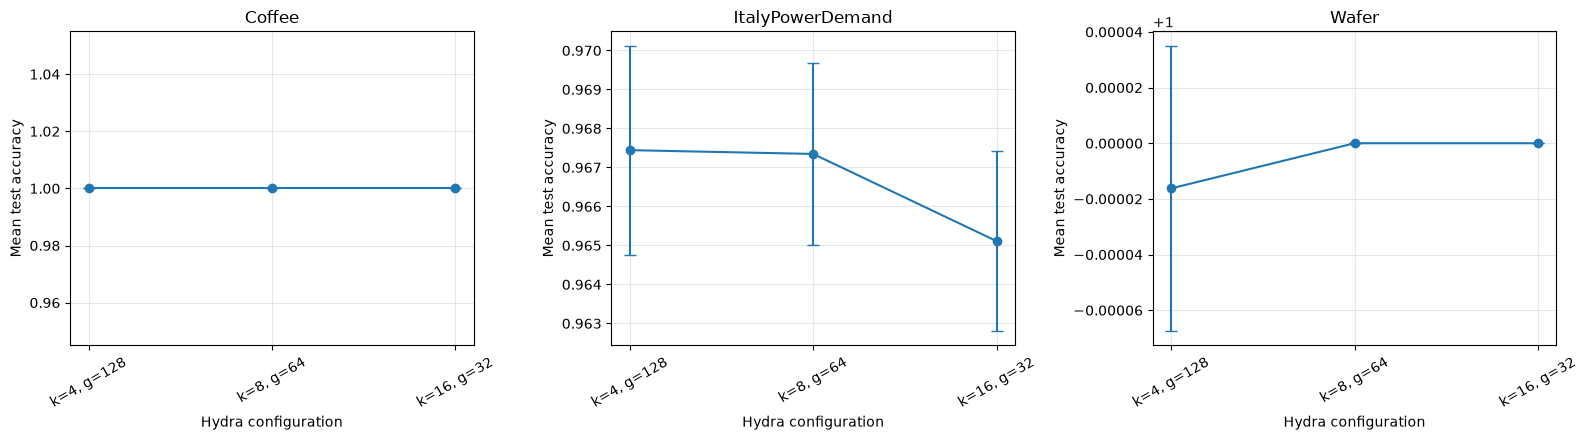

In [27]:
# Visualise the group-size experiment

fig, axes = plt.subplots(
    1,
    len(HYPERPARAM_DATASETS),
    figsize=(16, 4.5),
    squeeze=False,
)

for ax, dataset_name in zip(
    axes[0],
    HYPERPARAM_DATASETS,
):
    subset = kg_summary[
        kg_summary["dataset"] == dataset_name
    ].copy()

    subset = subset.set_index("config_name").reindex(
        [config["name"] for config in KG_CONFIGS]
    )

    labels = [
        f"k={config['k']}, g={config['g']}"
        for config in KG_CONFIGS
    ]

    means = subset["mean_accuracy"].to_numpy()
    stds = subset["std_accuracy"].fillna(0).to_numpy()

    ax.errorbar(
        labels,
        means,
        yerr=stds,
        marker="o",
        capsize=4,
    )

    ax.set_title(dataset_name)
    ax.set_ylabel("Mean test accuracy")
    ax.set_xlabel("Hydra configuration")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()